# Supplementary Fig. S13: Per-monkey results of neural markers of foraging strategy

[AI generated summary] Fig. 5e for each monkey separately (KA, PO): percentage of sessions supporting the standard RL (red), inferential RL (orange) or foraging (blue) hypothesis, or none of them (grey), per area. Only sessions with a delta-rule consistent within-target value update are counted (n per area). Same data and code as Fig. 5e (`fig5cde_across_target.ipynb`): the neural value is the projection of the population activity (averaged over 1.5–3.5 s, task engagement period) on the decision vector of a decoder of the previous outcome, fit separately for each chosen target; the hypotheses are tested by comparing its trial-to-trial change after rewarded and unrewarded trials within and across targets.

**How to run:** run all cells. Figures are saved in `figs/figS13/`.

**Results:** precomputed results are provided in `results/population_decoding/across_target_before_fb` (see the README). To recompute them, run in this folder: `python run_neural_value_across_target.py before_fb` (several hours on a server).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
##% title Imports
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

from helpers import get_data, merge_alter_values, make_session_summary, get_session_mean_value, extract_hypothesis
import popy.config as cfg
from popy.config import COLORS as COLORS
from popy.config import RESULTS_PATH

plt.rcParams.update({'font.size': 8})

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

In [3]:
def print_stats_both(stats_summary, printres=True, ax=None, title=None): 
    # Create horizontal bar plot showing proportions for each subregion
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=(1.2, 1.5))
    else:
        fig = ax.figure
    plt.rcParams.update({'font.size': 8})
    
    subregions = ['MCC', 'dLPFC', 'vLPFC'][::-1]
    ordered_hypotheses = ['Standard RL', 'Inferential RL', 'Foraging', 'none']
    all_hypotheses = stats_summary['hypothesis'].unique()
    ordered_hypotheses = ordered_hypotheses + [h for h in all_hypotheses if h not in ordered_hypotheses]
    ordered_hypotheses = ordered_hypotheses[::-1]  # Reverse order for plotting
    

    #hypotheses_all = stats_summary['hypothesis'].unique()
    #ordered_hypotheses = [h for h in ordered_hypotheses if h in hypotheses_all]  # Keep only hypotheses that are present in the data
    
    # Calculate proportions and plot bars with slight overlap
    bar_height = 0.23  # Height of each individual bar
    overlap_offset = 0.15  # How much each bar is offset (smaller = more overlap)
    subregion_spacing = 1.0  # Space between subregion groups
    subregion_totals = {}
    
    for s, subregion in enumerate(subregions):
        subregion_data = stats_summary[stats_summary['subregion'] == subregion]
        hypothesis_counts = {hypothesis: subregion_data[subregion_data['hypothesis'] == hypothesis]['count'].sum()
                             for hypothesis in ordered_hypotheses}
        total_sessions = subregion_data['count'].sum()
        subregion_totals[subregion] = int(total_sessions)
        
        # Calculate the center position for this subregion group
        base_y = s * subregion_spacing
        
        for h, hypothesis in enumerate(ordered_hypotheses):
            if hypothesis in hypothesis_counts:
                proportion = hypothesis_counts[hypothesis] / total_sessions
            else:
                proportion = 0
                
            if printres:
                print(f'Subregion: {subregion}, Hypothesis: {hypothesis}, Proportion: {proportion * 100:.1f}% ({hypothesis_counts.get(hypothesis, 0)}/{total_sessions} sessions)')
            
            # Calculate y position with overlap
            # Start from bottom and work up, with each bar slightly offset
            y_pos = base_y - (len(ordered_hypotheses) - 1) * overlap_offset / 2 + h * overlap_offset
            
            color = COLORS.get(hypothesis, 'gray')
            if hypothesis == 'Feedback coding':
                color = 'black'

            bar = ax.barh(y_pos, 
                    proportion * 100, 
                    height=bar_height, 
                    color=color, 
                    label=hypothesis if s == 0 else "",  # Only label once for legend
                    zorder=len(ordered_hypotheses) + h,  # Higher zorder for later hypotheses
                    alpha=0.8, 
                    edgecolor='grey', 
                    linewidth=0.5)
                
            # Add dot at the end of the bar
            ax.scatter(proportion * 100, y_pos, 
                        color=color, s=20, zorder=len(ordered_hypotheses) + h + 100,
                        edgecolor='black', linewidth=0.5)

    # Customize the plot
    ax.set_yticks([s * subregion_spacing for s in range(len(subregions))])
    ytick_labels = [f'{subregion}\nn={subregion_totals.get(subregion, 0)}' for subregion in subregions]
    ax.set_yticklabels(ytick_labels, rotation=0, va='center', ha='center')
    ax.set_xlabel('Percent sessions\n(%)')
    ax.set_xlim(-5, 105)
    # xticks at 0, 50, 100
    ax.set_xticks([0, 50, 100])


    ax.grid(axis='x', linestyle='--', alpha=0.5, zorder=-1)
    
    # Remove spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    #sns.despine(ax=ax, trim=True)
    
    # Create legend - only include hypotheses that actually appear in the data
    present_hypotheses = [h for h in ordered_hypotheses if h in stats_summary['hypothesis'].values]
    legend_handles = [plt.Rectangle((0,0),1,1, 
                                  facecolor=COLORS.get(hypothesis, 'gray'), 
                                  alpha=0.8, 
                                  edgecolor='grey', 
                                  linewidth=0.5) 
                     for hypothesis in present_hypotheses]
    
    if ax is None:
        fig.legend(legend_handles[::-1], present_hypotheses[::-1], loc='center left', bbox_to_anchor=(1, 0.5))
    
    if title is not None:
        ax.set_title(title, fontsize=10)

    return fig, ax, legend_handles, present_hypotheses

---
# Get data

In [4]:
base_path = os.path.join(FIGS_PATH, 'figS13')  # figures are saved here
os.makedirs(base_path, exist_ok=True)

In [5]:
res = get_data(floc=os.path.join(RESULTS_PATH, 'population_decoding', 'across_target_before_fb'))
res['monkey'] = res['monkey'].astype(str)
res['session'] = res['session'].astype(str)
res['subregion'] = res['subregion'].astype(str)

res

,trial_id,target,feedback,type,V_neural,V_neural_p1,dV_neural,V_behav,V_behav_p1,dV_behav,monkey,session,subregion
41235,8,2.0,1,alter,0.358216,0.046304,-0.311912,0.7208974122600382,0.8436938600723682,-0.122796,ka,010720,MCC
41236,8,2.0,1,within,0.470415,-0.027992,-0.498406,0.7208974122600382,0.8436938600723682,-0.122796,ka,010720,MCC
41237,8,2.0,1,alter,0.518198,0.106536,-0.411662,0.7208974122600382,0.8436938600723682,-0.122796,ka,010720,MCC
41238,9,2.0,1,alter,0.046304,0.100147,0.053843,0.8436938600723682,0.9124636945256874,-0.068770,ka,010720,MCC
41239,9,2.0,1,within,-0.027992,0.681812,0.709804,0.8436938600723682,0.9124636945256874,-0.068770,ka,010720,MCC
...,...,...,...,...,...,...,...,...,...,...,...,...,...
168721,421,1.0,1,alter,-0.039676,0.165310,0.204986,0.5909338740218392,0.7111940631746023,-0.120260,po,310822,dLPFC
168722,421,1.0,1,alter,0.114085,-0.035239,-0.149324,0.5909338740218392,0.7111940631746023,-0.120260,po,310822,dLPFC
168723,422,1.0,1,within,-0.009429,0.012456,0.021885,0.7111940631746023,0.7960993007031616,-0.084905,po,310822,dLPFC
168724,422,1.0,1,alter,0.165310,-0.066209,-0.231519,0.7111940631746023,0.7960993007031616,-0.084905,po,310822,dLPFC


In [6]:
# Get data
res = merge_alter_values(res) # Merge 'alter' type rows by averaging their values for each trial, so that we only have one
res 

,monkey,session,subregion,trial_id,type,feedback,dV_neural,V_neural,V_neural_p1
0,ka,010720,MCC,8,within,1,-0.498406,0.470415,-0.027992
1,ka,010720,MCC,8,alter,1,-0.361787,0.438207,0.076420
2,ka,010720,MCC,9,within,1,0.709804,-0.027992,0.681812
3,ka,010720,MCC,9,alter,1,0.329899,0.076420,0.406319
4,ka,010720,MCC,10,within,1,-0.294047,0.681812,0.387766
...,...,...,...,...,...,...,...,...,...
113891,po,310822,dLPFC,420,alter,1,0.114306,-0.077102,0.037205
113892,po,310822,dLPFC,421,within,1,-0.192317,0.182888,-0.009429
113893,po,310822,dLPFC,421,alter,1,0.027831,0.037205,0.065036
113894,po,310822,dLPFC,422,within,1,0.021885,-0.009429,0.012456


---
# Value-coding hypothesis in the within-target condition

The same test as in Fig. 4 (delta-rule consistent update), in the within-target condition; only the delta-rule consistent sessions are used below.

In [7]:
# summarize value coding hypothesis per session
session_summary = make_session_summary(res)
session_summary

,monkey,session,subregion,hypothesis
0,ka,010720,MCC,Delta rule (strict)
1,ka,010720,vLPFC,Delta rule (loose)
2,ka,010822,MCC,Delta rule (loose)
3,ka,010822,dLPFC,Other
4,ka,010922,MCC,Other
...,...,...,...,...
197,po,300322,vLPFC,Other
198,po,300421,MCC,Delta rule (loose)
199,po,300421,dLPFC,Feedback
200,po,310822,MCC,Other


In [8]:
# get mean modulation per session
results_df_mean = get_session_mean_value(res, session_summary)
results_df_mean

,monkey,session,subregion,type,feedback,dV_neural,V_neural,V_neural_p1,dV_signif,value_coding
0,ka,010720,MCC,alter,1,0.111676,0.044528,0.156204,True,Delta rule (strict)
1,ka,010720,MCC,alter,0,-0.121358,0.044960,-0.076399,True,Delta rule (strict)
2,ka,010720,MCC,within,1,0.121374,0.079801,0.201175,True,Delta rule (strict)
3,ka,010720,MCC,within,0,-0.146974,0.010909,-0.136065,True,Delta rule (strict)
4,ka,010720,vLPFC,alter,1,0.014721,-0.020156,-0.005435,False,Delta rule (loose)
...,...,...,...,...,...,...,...,...,...,...
803,po,310822,MCC,within,1,-0.016811,0.066171,0.049360,False,Other
804,po,310822,dLPFC,alter,0,-0.002223,-0.025594,-0.027817,False,Other
805,po,310822,dLPFC,alter,1,0.009231,-0.018640,-0.009408,False,Other
806,po,310822,dLPFC,within,0,0.035507,-0.024893,0.010613,False,Other


In [9]:
# use only delta consistent sessions
is_delta = results_df_mean['value_coding'].isin(['Delta rule (loose)', 'Delta rule (strict)'])
results_df_mean_delta = results_df_mean[is_delta]

# print num session per area that is is_delta
for subregion in results_df_mean['subregion'].unique():
    for monkey in results_df_mean['monkey'].unique():
        data_total = results_df_mean.loc[(results_df_mean['subregion'] == subregion) & (results_df_mean['monkey'] == monkey)]
        data_delta = results_df_mean_delta.loc[(results_df_mean_delta['subregion'] == subregion) & (results_df_mean_delta['monkey'] == monkey)]
        n_sessions_total = len(np.unique(data_total.session))
        n_sessions_delta = len(np.unique(data_delta.session))
        print(monkey, subregion, f"{n_sessions_delta}/{n_sessions_total} sessions are delta consistent")

ka MCC 37/58 sessions are delta consistent
po MCC 26/45 sessions are delta consistent
ka vLPFC 4/12 sessions are delta consistent
po vLPFC 3/6 sessions are delta consistent
ka dLPFC 14/46 sessions are delta consistent
po dLPFC 8/35 sessions are delta consistent


---
# Supplementary Fig. S13, Fraction of sessions per hypothesis, per monkey

Subregion: vLPFC, Hypothesis: none, Proportion: 25.0% (1/4 sessions)
Subregion: vLPFC, Hypothesis: Foraging, Proportion: 75.0% (3/4 sessions)
Subregion: vLPFC, Hypothesis: Inferential RL, Proportion: 0.0% (0/4 sessions)
Subregion: vLPFC, Hypothesis: Standard RL, Proportion: 0.0% (0/4 sessions)
Subregion: dLPFC, Hypothesis: none, Proportion: 42.9% (6/14 sessions)
Subregion: dLPFC, Hypothesis: Foraging, Proportion: 42.9% (6/14 sessions)
Subregion: dLPFC, Hypothesis: Inferential RL, Proportion: 0.0% (0/14 sessions)
Subregion: dLPFC, Hypothesis: Standard RL, Proportion: 14.3% (2/14 sessions)
Subregion: MCC, Hypothesis: none, Proportion: 13.5% (5/37 sessions)
Subregion: MCC, Hypothesis: Foraging, Proportion: 81.1% (30/37 sessions)
Subregion: MCC, Hypothesis: Inferential RL, Proportion: 0.0% (0/37 sessions)
Subregion: MCC, Hypothesis: Standard RL, Proportion: 5.4% (2/37 sessions)
Subregion: vLPFC, Hypothesis: none, Proportion: 33.3% (1/3 sessions)
Subregion: vLPFC, Hypothesis: Foraging, Prop

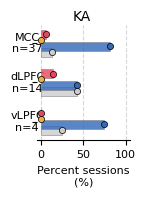

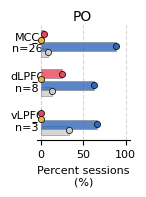

In [10]:
# Extract hypothesis info

stats_df = extract_hypothesis(results_df_mean_delta, detailed=False)

stats_df

# print stats

fig_bar_ka, _, _, _ = print_stats_both(stats_df.loc[stats_df['monkey'] == 'ka'])
fig_bar_po, _, _, _ = print_stats_both(stats_df.loc[stats_df['monkey'] == 'po'])

fig_bar_ka.suptitle('KA', fontsize=10)
fig_bar_po.suptitle('PO', fontsize=10)

# save figure
fig_bar_ka.savefig(os.path.join(base_path, 'RL_forage_bars_ka.svg'), format='svg', bbox_inches='tight', dpi=300, transparent=True)
fig_bar_po.savefig(os.path.join(base_path, 'RL_forage_bars_po.svg'), format='svg', bbox_inches='tight', dpi=300, transparent=True)

In [11]:
# Export source data (Supplementary Figure 13)
from popy.source_data import export_source_data

tables_s13 = {}
for monkey in ['ka', 'po']:
    counts = stats_df.loc[stats_df['monkey'] == monkey].groupby(['subregion', 'hypothesis'])['count'].sum()  # as in fig_bar_{monkey}
    rows = []
    for subregion in ['MCC', 'dLPFC', 'vLPFC']:
        n_total = int(counts.loc[subregion].sum())
        for hypothesis in ['Standard RL', 'Inferential RL', 'Foraging', 'none']:
            n = int(counts.get((subregion, hypothesis), 0))
            rows.append({'Monkey': monkey.upper(), 'Area': subregion,
                         'Hypothesis': 'None of the hypotheses' if hypothesis == 'none' else hypothesis,
                         'n sessions supporting the hypothesis': n, 'n sessions (total)': n_total,
                         'Percent sessions (%)': 100 * n / n_total})
    tables_s13[f'Monkey {monkey.upper()}'] = pd.DataFrame(rows)

export_source_data(
    'Supplementary Figure 13',
    tables_s13,
    'Fig. 5e for each monkey (left: KA, right: PO): percentage of sessions supporting each hypothesis, relative to the '
    'sessions of that monkey with within-target delta-rule-consistent value coding (n sessions (total)); neural value '
    'averaged over 1.5-3.5 s of the trial (task engagement period). Standard RL: significant positive within-target and non-significant across-target feedback modulation of Delta V_neural; Inferential RL: significant positive within-target and significant negative across-target modulation; Foraging: significant positive modulation in both; None: all other sessions (two-sided Mann-Whitney U test over trials, rewarded vs. unrewarded, p < 0.05).',
)

Supplementary Figure 13: source data saved (12 rows, 12 rows)
